# ADMET-Engine v3.0 (*CardioPhys-3D*) — WP1 & WP2 Colab GPU Worker

Stateless Google Colab Pro worker for **ADMET-Engine v3.0** (`github.com/JakobFerschin/Admet-Engine`):
1. **WP1 (Multi-Channel ChEMBL v37 + pH 7.4 3D Conformers):** Streams censored (`=`, `>`, `<`) bioactivities for **hERG** (`CHEMBL240`), **Cav1.2** (`CHEMBL1940`), and **Nav1.5** (`CHEMBL1980`), enforces a zero-overlap Bemis–Murcko scaffold split, protonates molecules at physiological pH 7.4, and generates MMFF94s Boltzmann-weighted 3D conformer ensembles in parallel via `joblib`.
2. **WP2 (Differentiable FDA-CiPA Cardiomyocyte ODE on GPU):** Runs all 28 official FDA-CiPA reference drugs ($28 \times 4 = 112$ action potential trajectories) in parallel on CUDA GPU, computes `qNet` & `APD90`, proves multi-channel rescue on **Verapamil** & **Ranolazine**, and plots publication-grade action potential waveforms.

> **Runtime tip:** Select `Runtime -> Change runtime type -> T4 / L4 / A100 GPU` (High-RAM recommended for full 3D conformer generation).

In [1]:
# @title 1. Clone / Sync Repo & Install Dependencies
import os, subprocess, sys, torch

REPO_DIR = '/content/Admet-Engine'
if not os.path.exists(REPO_DIR):
    !git clone https://github.com/JakobFerschin/Admet-Engine.git {REPO_DIR}
else:
    !git -C {REPO_DIR} pull --ff-only

%cd {REPO_DIR}
!pip install -q rdkit torch-geometric joblib scikit-learn requests matplotlib

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device} | PyTorch: {torch.__version__} | CPUs: {os.cpu_count()}')
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Already up to date.
/content/Admet-Engine
Device: cuda | PyTorch: 2.14.1+cu130 | CPUs: 2
GPU: Tesla T4


In [2]:
# @title 2. WP2 — GPU-Vectorized FDA-CiPA 28 Cardiomyocyte Validation
import sys, time
sys.path.insert(0, '/content/Admet-Engine/src')

import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from physiology import CardiomyocyteSimulator, ChannelBlockProfile, CIPA_28_DRUGS

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sim = CardiomyocyteSimulator(dt_ms=0.2, n_beats=2).to(device)

def _t(vals):
    return torch.tensor([1e6 if v is None else float(v) for v in vals], dtype=torch.float32, device=device)

t0 = time.perf_counter()
out = sim.simulate_cipa_protocol(
    cmax_free_uM=_t([d.cmax_free_uM for d in CIPA_28_DRUGS]),
    ic50_herg_uM=_t([d.ic50_herg_uM for d in CIPA_28_DRUGS]),
    ic50_cav12_uM=_t([d.ic50_cav12_uM for d in CIPA_28_DRUGS]),
    ic50_nav15_late_uM=_t([d.ic50_nav15_late_uM for d in CIPA_28_DRUGS]),
    ic50_nav15_peak_uM=_t([d.ic50_nav15_peak_uM for d in CIPA_28_DRUGS]),
    h_herg=_t([d.h_herg for d in CIPA_28_DRUGS]),
    h_cav12=_t([d.h_cav12 for d in CIPA_28_DRUGS]),
    h_nav15_late=_t([d.h_nav15_late for d in CIPA_28_DRUGS]),
    h_nav15_peak=_t([d.h_nav15_peak for d in CIPA_28_DRUGS]),
)
if device.type == 'cuda':
    torch.cuda.synchronize()
elapsed = time.perf_counter() - t0

qnets = out['mean_qnet'].detach().cpu().numpy()
apds = out['apd90_1x_ms'].detach().cpu().numpy()
risks = [d.tdp_risk for d in CIPA_28_DRUGS]

y_hi_int = [1 if r in ('High', 'Intermediate') else 0 for r in risks]
y_hi_lo = [1 if r == 'High' else 0 for r in risks if r != 'Intermediate']
q_hi_lo = [-q for q, r in zip(qnets, risks) if r != 'Intermediate']
herg_ratio = [d.cmax_free_uM / (d.ic50_herg_uM or 1e6) for d in CIPA_28_DRUGS]
herg_hi_lo = [hr for hr, r in zip(herg_ratio, risks) if r != 'Intermediate']

print(f'Simulated 112 cardiomyocyte ODE trajectories on {device} in {elapsed:.2f}s!')
print(f'CiPA-ODE (-qNet) ROC-AUC (High+Int vs Low): {roc_auc_score(y_hi_int, -qnets):.4f}  (hERG-only: {roc_auc_score(y_hi_int, herg_ratio):.4f})')
print(f'CiPA-ODE (-qNet) ROC-AUC (High vs Low):     {roc_auc_score(y_hi_lo, q_hi_lo):.4f}  (hERG-only: {roc_auc_score(y_hi_lo, herg_hi_lo):.4f})')

Simulated 112 cardiomyocyte ODE trajectories on cuda in 51.07s!
CiPA-ODE (-qNet) ROC-AUC (High+Int vs Low): 0.9064  (hERG-only: 0.8304)
CiPA-ODE (-qNet) ROC-AUC (High vs Low):     0.9861  (hERG-only: 0.9444)


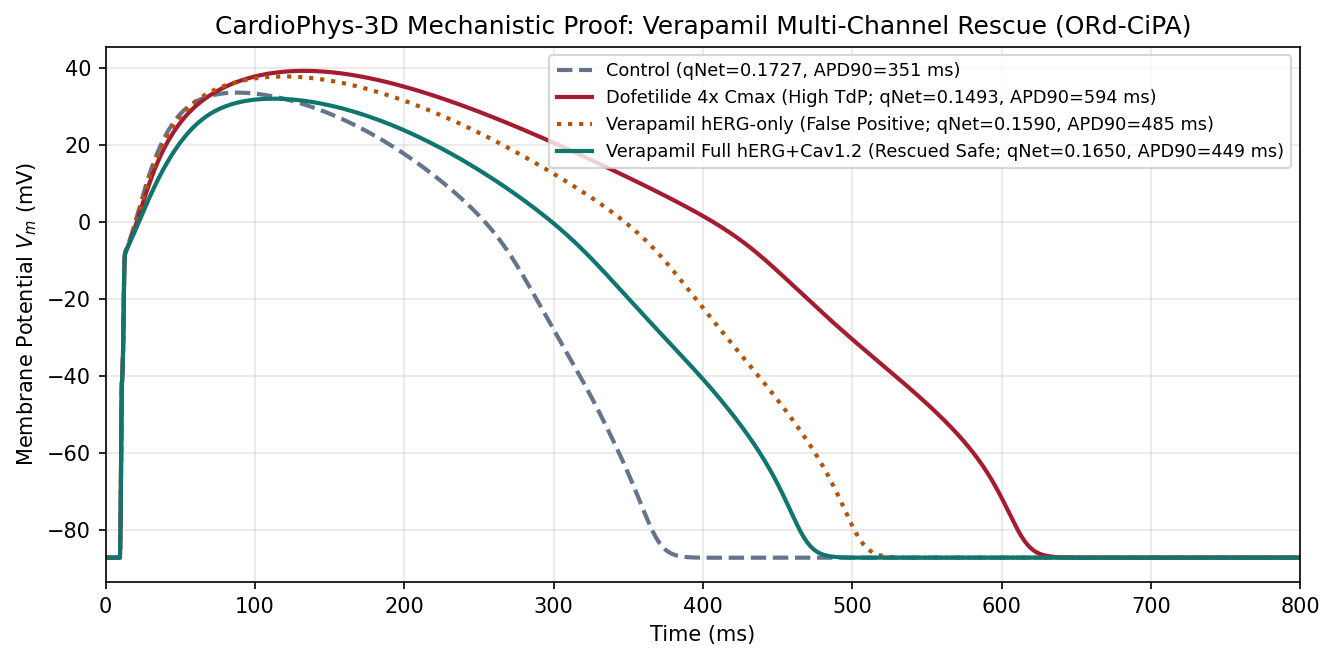

In [3]:
# @title 3. WP2 Figure — Verapamil Multi-Channel Rescue vs. Dofetilide Action Potentials
conc = torch.tensor([0.0, 0.008, 0.324, 0.324], device=device)  # Control, Dofetilide 4x, Verapamil hERG-only 4x, Verapamil Full 4x
herg = torch.tensor([1e6, 0.0049, 0.499, 0.499], device=device)
cav12 = torch.tensor([1e6, 1e6, 1e6, 0.202], device=device)

res = sim.simulate(
    ChannelBlockProfile.from_ic50_uM(conc_uM=conc, ic50_herg_uM=herg, ic50_cav12_uM=cav12),
    return_traces=True,
    trace_stride=2,
)

t = res.time_ms.cpu().numpy()
v = res.v_trace.cpu().numpy()
labels = [
    f'Control (qNet={res.qnet[0]:.4f}, APD90={res.apd90_ms[0]:.0f} ms)',
    f'Dofetilide 4x Cmax (High TdP; qNet={res.qnet[1]:.4f}, APD90={res.apd90_ms[1]:.0f} ms)',
    f'Verapamil hERG-only (False Positive; qNet={res.qnet[2]:.4f}, APD90={res.apd90_ms[2]:.0f} ms)',
    f'Verapamil Full hERG+Cav1.2 (Rescued Safe; qNet={res.qnet[3]:.4f}, APD90={res.apd90_ms[3]:.0f} ms)',
]
colors = ['#64748B', '#A51C30', '#B45309', '#0F766E']
styles = ['--', '-', ':', '-']

plt.figure(figsize=(9, 4.5), dpi=150)
for i in range(4):
    plt.plot(t, v[i], label=labels[i], color=colors[i], ls=styles[i], lw=2.0)
plt.xlim(0, 800)
plt.xlabel('Time (ms)')
plt.ylabel('Membrane Potential $V_m$ (mV)')
plt.title('CardioPhys-3D Mechanistic Proof: Verapamil Multi-Channel Rescue (ORd-CiPA)')
plt.grid(alpha=0.3)
plt.legend(fontsize=8.5, frameon=True)
plt.tight_layout()
plt.show()

In [4]:
# @title 4. WP1 — Extract Multi-Channel ChEMBL v37 (hERG, Cav1.2, Nav1.5) with Tobit Censored Bounds
# Set MAX_PER_TARGET = None for the full ChEMBL corpus (~25k-30k rows), or 2000 for a quick smoke test.
MAX_PER_TARGET = None  # @param {type:'raw'}

from data.multichannel_extractor import extract_from_rest_api, build_multichannel_dataset

raw_rows = extract_from_rest_api(max_per_target=MAX_PER_TARGET)
df_mc = build_multichannel_dataset(raw_rows)

OUT_CSV = '/content/Admet-Engine/data/processed/cardiophys_multichannel_v3.csv'
df_mc.to_csv(OUT_CSV, index=False)
print(f'Saved {len(df_mc):,} compounds to {OUT_CSV}')
df_mc.head()

Saved 18,575 compounds to /content/Admet-Engine/data/processed/cardiophys_multichannel_v3.csv


,canonical_smiles,murcko_scaffold,hERG_pIC50,hERG_censor,hERG_n_obs,Cav1.2_pIC50,Cav1.2_censor,Cav1.2_n_obs,Nav1.5_pIC50,Nav1.5_censor,Nav1.5_n_obs,split
0,CC(C(=O)N[C@]1(c2ccccc2)CC[C@@H](N2CCN(C(C)C)C...,O=C(Cc1ccccc1)NC1(c2ccccc2)CCC(N2CCNCC2)CC1,5.92,0.0,1,NaN,NaN,0,NaN,NaN,0,train
1,CC(C(=O)NC1(c2ccccc2)CCC(N2CCC3(CCCO3)CC2)CC1)...,O=C(Cc1ccccc1)NC1(c2ccccc2)CCC(N2CCC3(CCCO3)CC...,6.14,0.0,1,NaN,NaN,0,NaN,NaN,0,train
2,CC(C(=O)N[C@]1(c2ccccc2)CC[C@@H](N2CCC(c3ccc(F...,O=C(Cc1ccccc1)NC1(c2ccccc2)CCC(N2CCC(c3ccccc3)...,7.37,0.0,1,NaN,NaN,0,NaN,NaN,0,train
3,CC(C(=O)N[C@]1(c2ccccc2)CC[C@H](N2CCCCC2)CC1)c...,O=C(Cc1ccccc1)NC1(c2ccccc2)CCC(N2CCCCC2)CC1,5.92,0.0,1,NaN,NaN,0,NaN,NaN,0,train
4,CC1CCN([C@H]2CC[C@](NC(=O)C(C)c3cc(C(F)(F)F)cc...,O=C(Cc1ccccc1)NC1(c2ccccc2)CCC(N2CCCCC2)CC1,6.34,0.0,1,NaN,NaN,0,NaN,NaN,0,train


In [3]:
!pip install -q rdkit nvmolkit dimorphite-dl

In [5]:
import os
import sys
import glob
import pandas as pd
import torch
from tqdm.auto import tqdm
from rdkit import Chem
from rdkit.Chem import AllChem
from joblib import Parallel, delayed
from dimorphite_dl import protonate_smiles
from nvmolkit.embedMolecules import EmbedMolecules
from nvmolkit.mmffOptimization import (
    MMFFOptimizeMoleculesConfs,
    default_rdkit_mmff_properties,
)

# 0. Repo & Pfad sicherstellen
if not os.path.exists("/content/Admet-Engine"):
    !git clone https://github.com/JakobFerschin/Admet-Engine.git /content/Admet-Engine
for p in ["/content/Admet-Engine", "/content/Admet-Engine/src"]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

# df_mc automatisch laden, falls durch VM-Reset nicht im RAM
if "df_mc" not in globals():
    candidates = glob.glob("/content/Admet-Engine/data/**/*cardiophys*.csv", recursive=True) + \
                 glob.glob("/content/Admet-Engine/data/**/*.csv", recursive=True) + \
                 glob.glob("/content/Admet-Engine/data/**/*.parquet", recursive=True)
    df_mc = None
    for f in candidates:
        tmp = pd.read_parquet(f) if f.endswith(".parquet") else pd.read_csv(f)
        if "canonical_smiles" in tmp.columns and len(tmp) > 1000:
            df_mc = tmp
            print(f"Auto-loaded df_mc ({len(df_mc):,} rows) from {f}")
            break
    if df_mc is None:
        raise RuntimeError("df_mc nicht gefunden – bitte einmal 'Laufzeit -> Vorherige Zellen ausführen' klicken.")

NUM_CONFS = 10
GPU_BATCH_SIZE = 1024   # Bei CUDA Out-of-Memory auf 512 setzen
OUT_PT = "/content/Admet-Engine/data/processed/cardiophys_3d_conformers_v3.pt"
os.makedirs(os.path.dirname(OUT_PT), exist_ok=True)

smiles_list = df_mc["canonical_smiles"].tolist()

# 1. CPU-Prep: pH 7.4 Protonierung via dimorphite_dl + explizite Wasserstoffe
def _prep_mol(smi):
    try:
        prots = protonate_smiles(smi, ph_min=7.4, ph_max=7.4, max_variants=1)
        prot_smi = prots[0] if prots else smi
        mol = Chem.MolFromSmiles(prot_smi)
        if mol is None:
            return smi, None
        mol = Chem.AddHs(mol)
        return smi, mol
    except Exception:
        return smi, None

prepped = Parallel(n_jobs=-1)(
    delayed(_prep_mol)(s) for s in tqdm(smiles_list, desc="1/3 CPU Prep (pH 7.4 + AddHs)")
)
valid_items = [(s, m) for s, m in prepped if m is not None]

# 2. GPU-Konformer-Generierung & MMFF94s-Minimierung
params = AllChem.ETKDGv3()
params.randomSeed = 42

valid_3d = {}

for i in tqdm(range(0, len(valid_items), GPU_BATCH_SIZE), desc="2/3 GPU ETKDGv3 + MMFF94s"):
    batch = valid_items[i : i + GPU_BATCH_SIZE]
    batch_smis = [x[0] for x in batch]
    batch_mols = [x[1] for x in batch]

    EmbedMolecules(
        batch_mols,
        params=params,
        confsPerMolecule=NUM_CONFS,
        maxIterations=-1,
    )

    mmff_props = [default_rdkit_mmff_properties(m, mmffVariant="MMFF94s") for m in batch_mols]
    energies = MMFFOptimizeMoleculesConfs(
        batch_mols,
        maxIters=400,
        properties=mmff_props,
        nonBondedThreshold=100.0,
    )

    # 3. Extraktion in dein Torch-Dictionary
    for smi, mol, conf_energies in zip(batch_smis, batch_mols, energies):
        if mol.GetNumConformers() == 0 or not conf_energies:
            continue
        coords = torch.tensor(
            [mol.GetConformer(cid).GetPositions() for cid in range(mol.GetNumConformers())],
            dtype=torch.float32,
        )
        atomic_nums = torch.tensor(
            [atom.GetAtomicNum() for atom in mol.GetAtoms()],
            dtype=torch.long,
        )
        e_tensor = torch.tensor(conf_energies, dtype=torch.float32)

        valid_3d[smi] = {
            "coords": coords,           # Shape: [num_confs, num_atoms, 3]
            "atomic_nums": atomic_nums, # Shape: [num_atoms]
            "energies": e_tensor,       # Shape: [num_confs]
        }

    if (i // GPU_BATCH_SIZE) % 4 == 0 and i > 0:
        torch.save(valid_3d, OUT_PT)

torch.save(valid_3d, OUT_PT)
print(f"Saved {len(valid_3d):,} / {len(smiles_list):,} 3D conformer ensembles to {OUT_PT}")

Cloning into '/content/Admet-Engine'...
remote: Enumerating objects: 249, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 249 (delta 30), reused 63 (delta 18), pack-reused 168 (from 1)
Receiving objects: 100% (249/249), 63.67 MiB | 19.62 MiB/s, done.
Resolving deltas: 100% (52/52), done.


NameError: name 'df_mc' is not defined